# Modelo Analítico · Da base bruta à decisão
**Case B · Lance Certo S.A. (empresa fictícia) · Finanças Gerais e Tesouraria**
Tema: onde a Lance Certo ganha dinheiro e onde concentrar esforço em 2027
Base: `Case_B_Base_Lotes_Lance_Certo.xlsx` (aba *Lotes*, jan–set/2026)
Autor: Pedro Henrique Costa da Silva

---
## Resumo executivo
| | |
|---|---|
| **Pergunta** | Onde a Lance Certo ganha dinheiro e onde deve concentrar esforço em 2027? |
| **Resposta** | A receita vem de **Máquinas, Imóveis e Veículos** (~91% da comissão). Cada lote de **Imóveis** ofertado rende R$ 17,7 mil de comissão e cada lote de **Máquinas** R$ 12,9 mil, contra R$ 1,0 mil em Eletrônicos. O ponto fraco comum é a conversão: o **canal Presencial vende menos que o Online em todas as categorias** (50% vs 67%), com a maior distância em Imóveis (16% vs 37%). |
| **Decisão** | Priorizar 2027 em **recuperar a conversão do Presencial (começando por Imóveis e Máquinas)**, investigar a queda de setembro em Imóveis/Máquinas e corrigir a trava de qualidade da base (comissão e duplicatas) na origem. |

*(Valores conferidos na execução do notebook; ver seções 8 e 9.)*

## 1. Definição do Problema de Negócio
**Contexto.** A Lance Certo S.A. realiza leilões de cinco categorias de bens (Veículos, Eletrônicos, Máquinas, Sucatas e diversos, Imóveis) em dois canais (Online e Presencial). Ela ganha uma **comissão** sobre o valor arrematado (GMV) de cada lote vendido.

**Problema.** A diretoria comercial quer saber **onde a empresa ganha dinheiro e onde deve concentrar esforço em 2027**. A base foi exportada do sistema **sem tratamento** e pode conter inconsistências.

**Objetivos.**
1. Tratar a base **sem alterar o arquivo original** (todo o tratamento é feito em uma cópia dentro do notebook) e documentar cada decisão.
2. Montar 5 indicadores essenciais por categoria e canal.
3. Resumir a principal conclusão em 1 gráfico.
4. Entregar 3 insights acionáveis e uma decisão recomendada.

**Perguntas-chave.**
- P1. Que inconsistências existem na base e como foram tratadas?
- P2. Qual o desempenho (GMV, conversão, take rate, ticket médio, comissão por lote) por categoria e canal?
- P3. Como esses indicadores evoluem mês a mês?
- P4. Onde está a maior oportunidade de receita para 2027?

**Solução proposta.** Notebook padronizado (problema → dados → análise → decisão) com limpeza em cópia, relatório de qualidade antes/depois, KPIs, teste estatístico e simulação do potencial de ganho.

**Resultado esperado.** Uma recomendação priorizada, com número de impacto e premissas explícitas, que sirva de base para a apresentação (máx. 6 slides).

## 2. KPIs (nome, fórmula e referência)
O case não traz metas. Por isso a **referência** de cada indicador é a média da própria empresa, e a leitura é comparativa entre categorias e canais.

| KPI | Fórmula | Referência / leitura |
|---|---|---|
| **GMV** | soma de `valor_venda` dos lotes vendidos | Tamanho do negócio negociado |
| **Taxa de conversão** | lotes vendidos ÷ lotes ofertados | Média da empresa (calculada na seção 8) |
| **Take rate** | comissão ÷ GMV | Define quanto do GMV vira receita |
| **Ticket médio** | GMV ÷ lotes vendidos | Porte típico do lote |
| **Comissão por lote ofertado** | comissão ÷ lotes ofertados | Combina conversão, ticket e take rate: mostra quanto cada lote que entra no leilão rende |

> A comissão usada em todos os KPIs é a **comissão corrigida** (`valor_venda × comissao_pct`), explicada na seção 6.

## 3. Ficha dos dados (dicionário)
- **Fonte:** exportação do sistema da Lance Certo (empresa fictícia), arquivo `Case_B_Base_Lotes_Lance_Certo.xlsx`
- **Período:** 01/01/2026 a 30/09/2026
- **Granularidade:** 1 linha = 1 lote leiloado

| Coluna | Tipo | Significado |
|---|---|---|
| `id_lote` | texto | Código do lote |
| `data_leilao` | data | Data do leilão |
| `categoria` | texto | Categoria do bem |
| `uf` | texto | Estado do comitente |
| `canal` | texto | Online ou Presencial |
| `lance_inicial_R$` | número | Valor de abertura do lote |
| `vendido` | texto | S = vendido, N = não vendido |
| `valor_venda_R$` | número | Valor arrematado (GMV do lote); vazio quando não vendido |
| `comissao_pct` | número | Percentual de comissão cobrado; vazio quando não vendido |
| `comissao_R$` | número | Receita de comissão do lote; vazio quando não vendido |

## 4. Parâmetros e configurações

In [1]:
# --- Única célula de parâmetros: altere aqui caminhos e limites ---
from pathlib import Path                      # manipulação de caminhos

ARQUIVO = Path("Case_B_Base_Lotes_Lance_Certo.xlsx")   # base original (somente leitura)
ABA = "Lotes"                                  # aba com os lotes
PASTA_SAIDA = Path("saidas")                   # pasta de saída padronizada
SEED = 42                                      # semente para reprodutibilidade
TOL_COMISSAO = 0.011                           # diferença (R$) até a qual consideramos arredondamento
Z_LIMITE = 3                                   # limite de desvios padrão para outlier (média + 3 dp)
IQR_FATOR = 1.5                                # fator do critério de Tukey (IQR)
INICIO, FIM = "2026-01-01", "2026-09-30"       # período esperado da base

## 5. Importação das bibliotecas

In [2]:
import numpy as np                             # cálculo numérico
import pandas as pd                            # manipulação de tabelas
import matplotlib.pyplot as plt                # gráficos
import seaborn as sns                          # gráficos estatísticos
from scipy.stats import chi2_contingency       # teste qui-quadrado (conversão x canal)
import warnings                                # controle de avisos
warnings.filterwarnings("ignore")              # evita ruído visual no relatório

np.random.seed(SEED)                           # reprodutibilidade
sns.set_theme(style="whitegrid")               # estilo padrão dos gráficos
plt.rcParams["figure.figsize"] = (12, 6)       # tamanho padrão das figuras
plt.rcParams["axes.titlesize"] = 13            # tamanho dos títulos
PASTA_SAIDA.mkdir(exist_ok=True)               # cria a pasta de saída se não existir

# Registro das versões das bibliotecas (equivale ao %watermark --iversions)
import sys, matplotlib, scipy
print("Python    :", sys.version.split()[0])
for nome, mod in [("numpy", np), ("pandas", pd), ("matplotlib", matplotlib), ("seaborn", sns), ("scipy", scipy)]:
    print(f"{nome:<10}:", mod.__version__)

# Funções reutilizáveis de formatação (padrão brasileiro)
def brl(x, casas=0):
    # formata número como R$ com separador brasileiro
    return "R$ " + f"{x:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def pct(x, casas=1):
    # formata proporção como porcentagem brasileira
    return f"{x*100:.{casas}f}%".replace(".", ",")

Python    : 3.13.17
numpy     : 2.5.3
pandas    : 3.0.5
matplotlib: 3.11.2
seaborn   : 0.13.2
scipy     : 1.18.1


## 6. Carga e exploração dos dados
O arquivo original é **apenas lido**. Toda manipulação é feita em `df`, uma **cópia** de `df_raw`. O arquivo `.xlsx` nunca é regravado.

In [3]:
df_raw = pd.read_excel(ARQUIVO, sheet_name=ABA)   # leitura da base bruta (não será modificada)
df = df_raw.copy()                                # cópia de trabalho: todo tratamento acontece aqui

# Nomes de colunas simples (sem símbolo R$) para facilitar o código
df = df.rename(columns={
    "lance_inicial_R$": "lance_inicial",
    "valor_venda_R$": "valor_venda",
    "comissao_R$": "comissao_original",
})

print("Formato (linhas, colunas):", df.shape)     # tamanho da base
df.head()                                         # primeiras linhas

Formato (linhas, colunas): (5060, 10)


,id_lote,data_leilao,categoria,uf,canal,lance_inicial,vendido,valor_venda,comissao_pct,comissao_original
0,LT101190,2026-01-30,Veículos,RJ,Presencial,106673.13,N,NaN,NaN,NaN
1,LT102797,2026-07-19,Eletrônicos,PR,Online,14130.36,S,16652.98,0.13,2164.89
2,LT104608,2026-02-25,Veículos,SP,Online,36483.97,S,45369.22,0.05,2268.46
3,LT104246,2026-09-02,Veículos,BA,Presencial,71430.89,N,NaN,NaN,NaN
4,LT101523,2026-07-29,Máquinas,RJ,Online,166714.46,S,258204.24,0.10,25820.42


In [4]:
df.info()                                         # tipos e contagem de não nulos

<class 'pandas.DataFrame'>
RangeIndex: 5060 entries, 0 to 5059
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   id_lote            5060 non-null   str           
 1   data_leilao        5060 non-null   datetime64[us]
 2   categoria          5060 non-null   str           
 3   uf                 5060 non-null   str           
 4   canal              5060 non-null   str           
 5   lance_inicial      5060 non-null   float64       
 6   vendido            5060 non-null   str           
 7   valor_venda        3204 non-null   float64       
 8   comissao_pct       3204 non-null   float64       
 9   comissao_original  3204 non-null   float64       
dtypes: datetime64[us](1), float64(4), str(5)
memory usage: 395.4 KB


In [5]:
df.describe(include="all").T                      # estatísticas gerais de todas as colunas

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id_lote,5060,5000,LT101503,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
data_leilao,5060,NaN,NaN,NaN,2026-05-15 03:16:04.743083,2026-01-01 00:00:00,2026-03-09 00:00:00,2026-05-14 00:00:00,2026-07-22 00:00:00,2026-09-30 00:00:00,NaN
categoria,5060,5,Veículos,2045,NaN,NaN,NaN,NaN,NaN,NaN,NaN
uf,5060,9,SP,1710,NaN,NaN,NaN,NaN,NaN,NaN,NaN
canal,5060,2,Online,3963,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lance_inicial,5060.0,NaN,NaN,NaN,130764.875996,1020.45,13896.9175,49741.82,108557.605,1495215.43,244050.905019
vendido,5060,2,S,3204,NaN,NaN,NaN,NaN,NaN,NaN,NaN
valor_venda,3204.0,NaN,NaN,NaN,120876.174632,1086.86,14862.4625,47289.86,118673.39,2092818.68,239462.032408
comissao_pct,3204.0,NaN,NaN,NaN,0.086223,0.05,0.06,0.09,0.11,0.13,0.027424
comissao_original,3204.0,NaN,NaN,NaN,8343.926726,130.42,1591.42,3462.61,7321.415,104640.93,13945.965912


In [6]:
# Distribuição das variáveis categóricas
for col in ["categoria", "uf", "canal", "vendido"]:
    print(df[col].value_counts(dropna=False).to_string(), "\n")

categoria
Veículos              2045
Eletrônicos           1114
Máquinas               767
Sucatas e diversos     743
Imóveis                391 

uf
SP    1710
MG     702
RJ     646
PR     357
RS     352
SC     335
BA     328
GO     317
PE     313 

canal
Online        3963
Presencial    1097 

vendido
S    3204
N    1856 



## 7. Diagnóstico de qualidade (antes da limpeza)
Cada teste abaixo tenta responder uma dúvida levantada na exploração da base. Nada é alterado nesta etapa.

### 7.1 Lance inicial preenchido e valor de venda vazio está correto?
Em leilão, o **lance inicial** é o valor de **abertura**. Ele existe para todo lote que entra no leilão. Se ninguém dá lance (ou não se atinge o mínimo), o lote **fica sem arrematante**: não há venda, logo não há valor de venda nem comissão. Então **não é erro**, é o que a coluna `vendido = N` representa. O teste abaixo confirma que a regra é respeitada em toda a base.

In [7]:
nao_vend = df["vendido"] == "N"                                         # lotes não vendidos
vend = df["vendido"] == "S"                                             # lotes vendidos

print("Não vendidos COM valor de venda   :", df.loc[nao_vend, "valor_venda"].notna().sum())      # esperado: 0
print("Não vendidos COM comissão         :", df.loc[nao_vend, "comissao_original"].notna().sum())  # esperado: 0
print("Vendidos SEM valor de venda       :", df.loc[vend, "valor_venda"].isna().sum())            # esperado: 0
print("Vendidos SEM comissão             :", df.loc[vend, "comissao_original"].isna().sum())      # esperado: 0
print("Vendas ABAIXO do lance inicial    :", (df.loc[vend, "valor_venda"] < df.loc[vend, "lance_inicial"]).sum())  # esperado: 0
print("Lance inicial nulo ou <= 0        :", (df["lance_inicial"].isna() | (df["lance_inicial"] <= 0)).sum())      # esperado: 0
print("\nConclusão: os vazios de valor de venda ocorrem apenas nos lotes não vendidos, como esperado.")

Não vendidos COM valor de venda   : 0
Não vendidos COM comissão         : 0
Vendidos SEM valor de venda       : 0
Vendidos SEM comissão             : 0
Vendas ABAIXO do lance inicial    : 0
Lance inicial nulo ou <= 0        : 0

Conclusão: os vazios de valor de venda ocorrem apenas nos lotes não vendidos, como esperado.


### 7.2 Linhas duplicadas

In [8]:
dup_linhas = df.duplicated(keep=False)                                  # marca todas as linhas que se repetem por completo
dup_id = df["id_lote"].duplicated(keep=False)                           # marca todos os ids repetidos

print("Linhas repetidas por completo (excedentes):", df.duplicated().sum())
print("IDs repetidos (excedentes)                 :", df["id_lote"].duplicated().sum())
print("Duplicatas de id que NÃO são cópia exata   :", (df["id_lote"].duplicated().sum() - df.duplicated().sum()))

df[dup_linhas].sort_values("id_lote").head(10)                          # amostra dos pares duplicados

Linhas repetidas por completo (excedentes): 60
IDs repetidos (excedentes)                 : 60
Duplicatas de id que NÃO são cópia exata   : 0


,id_lote,data_leilao,categoria,uf,canal,lance_inicial,vendido,valor_venda,comissao_pct,comissao_original
1903,LT100046,2026-07-24,Eletrônicos,SP,Online,12811.26,S,13023.42,0.12,1562.81
3497,LT100046,2026-07-24,Eletrônicos,SP,Online,12811.26,S,13023.42,0.12,1562.81
4917,LT100063,2026-08-14,Veículos,SP,Online,45001.46,S,53633.90,0.07,3754.37
1088,LT100063,2026-08-14,Veículos,SP,Online,45001.46,S,53633.90,0.07,3754.37
306,LT100088,2026-02-21,Veículos,RJ,Presencial,46105.88,S,54467.67,0.07,3812.74
4331,LT100088,2026-02-21,Veículos,RJ,Presencial,46105.88,S,54467.67,0.07,3812.74
1887,LT100112,2026-09-18,Sucatas e diversos,MG,Online,7187.32,S,10519.40,0.10,1051.94
316,LT100112,2026-09-18,Sucatas e diversos,MG,Online,7187.32,S,10519.40,0.10,1051.94
3285,LT100148,2026-03-09,Sucatas e diversos,SP,Online,32019.42,S,38239.60,0.09,3441.56
4624,LT100148,2026-03-09,Sucatas e diversos,SP,Online,32019.42,S,38239.60,0.09,3441.56


Cada `id_lote` repetido é uma **cópia exata** da linha (mesma data, categoria, valores). Um lote só pode ser leiloado uma vez, então a repetição **infla lotes, GMV e comissão** e deve ser removida.

### 7.3 Comissão: `valor_venda × comissao_pct` bate com `comissao_R$`?

In [9]:
dv = df[vend].drop_duplicates().copy()                                  # só vendidos, sem duplicatas, para o teste
dv["comissao_calc"] = (dv["valor_venda"] * dv["comissao_pct"].round(2)).round(2) # comissão recalculada (pct sem ruído de ponto flutuante)
dv["diferenca"] = dv["comissao_original"] - dv["comissao_calc"]         # original menos recalculada
dv["abs_dif"] = dv["diferenca"].abs()                                   # tamanho da diferença

print("Vendas com diferença > 0           :", (dv["abs_dif"] > 0).sum())
print("  até R$ 0,01 (arredondamento)     :", ((dv["abs_dif"] > 0) & (dv["abs_dif"] <= TOL_COMISSAO)).sum())
print("  acima de R$ 0,01 (erro real)     :", (dv["abs_dif"] > TOL_COMISSAO).sum())

erros = dv[dv["abs_dif"] > TOL_COMISSAO].copy()                         # os erros reais
erros["razao_original_calc"] = (erros["comissao_original"] / erros["comissao_calc"]).round(2)  # quantas vezes maior
print("\nRazão comissão original ÷ recalculada nos erros reais:")
print(erros["razao_original_calc"].value_counts().to_string())
erros[["id_lote", "valor_venda", "comissao_pct", "comissao_original", "comissao_calc", "diferenca"]].head(15)

Vendas com diferença > 0           : 50
  até R$ 0,01 (arredondamento)     : 35
  acima de R$ 0,01 (erro real)     : 15

Razão comissão original ÷ recalculada nos erros reais:
razao_original_calc
10.0    15


,id_lote,valor_venda,comissao_pct,comissao_original,comissao_calc,diferenca
245,LT101611,10766.60,0.11,11843.3,1184.33,10658.97
517,LT101428,10732.82,0.12,12879.4,1287.94,11591.46
1603,LT101272,47342.36,0.07,33139.7,3313.97,29825.73
1812,LT104468,8841.09,0.09,7957.0,795.70,7161.30
1983,LT103590,13887.71,0.13,18054.0,1805.40,16248.60
2146,LT101930,36304.57,0.07,25413.2,2541.32,22871.88
2401,LT104935,122262.90,0.05,61131.4,6113.14,55018.26
2577,LT104415,116491.98,0.06,69895.2,6989.52,62905.68
2769,LT100025,63443.73,0.09,57099.4,5709.94,51389.46
2785,LT104979,13777.01,0.12,16532.4,1653.24,14879.16


**Leitura.** Existem dois fenômenos diferentes:
- **Diferenças de ±R$ 0,01:** arredondamento de centavos. Impacto desprezível.
- **Erros reais:** a comissão original está **exatamente 10 vezes maior** que a recalculada (erro de casa decimal na origem). Esses poucos lotes inflam a receita em centenas de milhares de reais, então **precisam** ser corrigidos.

**Decisão:** criar a coluna `comissao_corrigida = valor_venda × comissao_pct` (arredondada em 2 casas) e usá-la em todos os indicadores. A coluna original fica preservada para auditoria.

### 7.4 Percentual de comissão por categoria (regra de negócio)
A comissão parece seguir uma faixa por categoria. Se for verdade, qualquer percentual fora da faixa seria suspeito.

In [10]:
dv["comissao_pct_r"] = dv["comissao_pct"].round(2)                      # remove ruído de ponto flutuante (ex.: 0.0999999)
faixa = dv.groupby("categoria")["comissao_pct_r"].agg(["min", "max", "mean", "nunique"]).round(3)  # faixa por categoria
faixa

,min,max,mean,nunique
categoria,,,,
Eletrônicos,0.11,0.13,0.121,3
Imóveis,0.05,0.05,0.050,1
Máquinas,0.08,0.10,0.090,3
Sucatas e diversos,0.09,0.11,0.100,3
Veículos,0.05,0.07,0.060,3


Cada categoria opera em uma faixa estreita (ex.: Imóveis 5% fixo, Eletrônicos 11% a 13%), sem percentual fora do padrão. O **take rate da empresa depende, portanto, do mix de categorias**.

### 7.5 Outliers: o que é valor extremo e o que é só escala diferente?
A base mistura bens de preços muito diferentes (um eletrônico de R$ 8 mil e um imóvel de R$ 1 milhão). Olhar a base inteira de uma vez faz parecer que há outliers, quando é só diferença de escala. O critério correto é **comparar cada lote com a própria categoria** (z-score e IQR por categoria).

In [11]:
base_out = df.drop_duplicates().copy()                                  # base sem duplicatas para medir outliers

# 1) Visão global (enganosa): média, mediana, desvio padrão
print("GLOBAL  média:", brl(base_out['lance_inicial'].mean()), "| mediana:", brl(base_out['lance_inicial'].median()),
      "| desvio padrão:", brl(base_out['lance_inicial'].std()))
z_global = ((base_out["lance_inicial"] - base_out["lance_inicial"].mean()) / base_out["lance_inicial"].std()).abs()
print("GLOBAL  lotes com |z| > 3:", (z_global > Z_LIMITE).sum(), "| por categoria:", base_out.loc[z_global > Z_LIMITE, "categoria"].value_counts().to_dict(), "(efeito de escala)\n")

# 2) Visão correta: dentro de cada categoria
def outliers_por_categoria(frame, coluna):
    # conta outliers por categoria usando z-score e IQR (Tukey)
    linhas = []
    for cat, g in frame.groupby("categoria"):
        x = g[coluna].dropna()                                          # valores da categoria
        z = ((x - x.mean()) / x.std()).abs()                            # z-score dentro da categoria
        q1, q3 = x.quantile([0.25, 0.75])                               # quartis
        iqr = q3 - q1                                                   # amplitude interquartil
        fora_iqr = ((x < q1 - IQR_FATOR*iqr) | (x > q3 + IQR_FATOR*iqr)).sum()
        linhas.append({"categoria": cat, "n": len(x), "média": x.mean(), "mediana": x.median(),
                       "desvio_padrão": x.std(), "mínimo": x.min(), "máximo": x.max(),
                       "assimetria": x.skew(), "outliers_z>3": int((z > Z_LIMITE).sum()), "outliers_IQR": int(fora_iqr)})
    return pd.DataFrame(linhas).set_index("categoria").round(2)

print("Outliers de LANCE INICIAL por categoria:")
display(outliers_por_categoria(base_out, "lance_inicial"))
print("Outliers de VALOR DE VENDA por categoria:")
display(outliers_por_categoria(base_out[base_out['vendido'] == 'S'], "valor_venda"))

GLOBAL  média: R$ 130.762 | mediana: R$ 49.810 | desvio padrão: R$ 244.238
GLOBAL  lotes com |z| > 3: 186 | por categoria: {'Imóveis': 186} (efeito de escala)

Outliers de LANCE INICIAL por categoria:


,n,média,mediana,desvio_padrão,mínimo,máximo,assimetria,outliers_z>3,outliers_IQR
categoria,,,,,,,,,
Eletrônicos,1100,8089.96,8145.94,4031.90,1020.45,14969.26,-0.01,0,0
Imóveis,385,835694.56,838418.18,386005.66,151885.76,1495215.43,-0.06,0,0
Máquinas,761,223438.55,224802.93,101716.85,40012.86,399685.82,-0.07,0,0
Sucatas e diversos,734,20770.74,20597.56,10922.92,2007.43,39993.20,0.04,0,0
Veículos,2020,68260.48,68488.83,30167.50,15072.20,119942.98,-0.02,0,0


Outliers de VALOR DE VENDA por categoria:


,n,média,mediana,desvio_padrão,mínimo,máximo,assimetria,outliers_z>3,outliers_IQR
categoria,,,,,,,,,
Eletrônicos,872,10462.44,10197.30,5461.96,1086.86,23556.20,0.15,0,0
Imóveis,127,1074012.33,1048658.34,475281.61,204194.68,2092818.68,0.16,0,0
Máquinas,383,284312.69,282345.86,138687.58,47049.43,588536.22,0.13,0,0
Sucatas e diversos,504,26671.07,25313.36,14892.33,2325.38,63328.31,0.27,0,0
Veículos,1278,88850.00,87797.40,41327.06,15900.78,189194.41,0.24,0,0


count    3164.000
mean        1.299
std         0.171
min         1.000
25%         1.151
50%         1.295
75%         1.447
max         1.600
dtype: float64


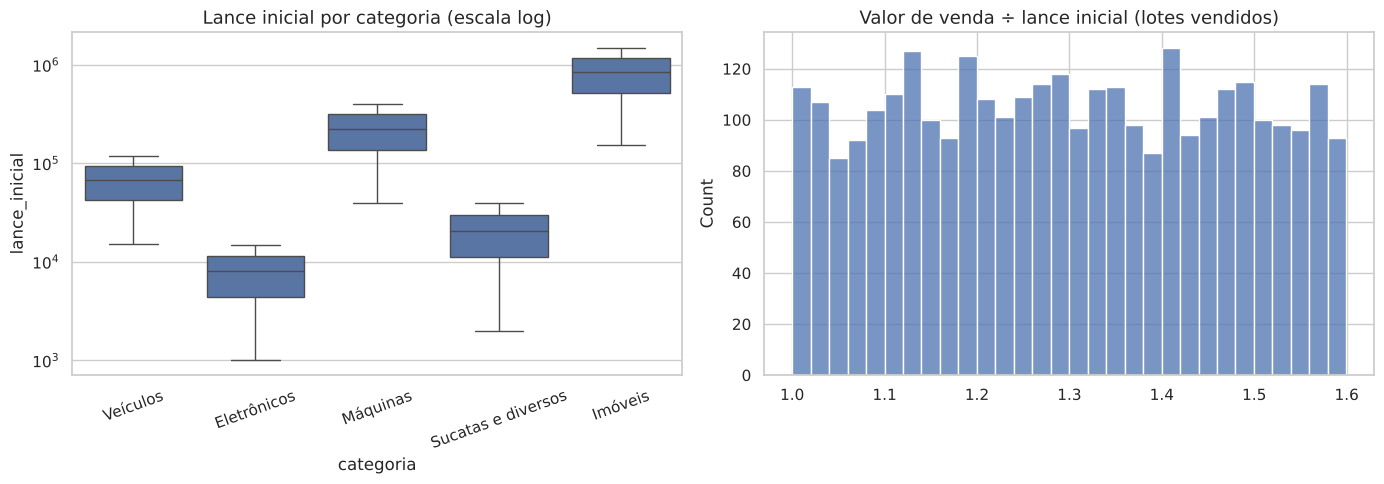

In [12]:
# Razão venda ÷ lance inicial: um valor de venda absurdo apareceria aqui
razao = base_out.loc[base_out["vendido"] == "S", "valor_venda"] / base_out.loc[base_out["vendido"] == "S", "lance_inicial"]
print(razao.describe().round(3))

# Boxplot por categoria em escala logarítmica (mostra que cada categoria é homogênea)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=base_out, x="categoria", y="lance_inicial", ax=ax[0])
ax[0].set_yscale("log"); ax[0].set_title("Lance inicial por categoria (escala log)"); ax[0].tick_params(axis="x", rotation=20)
sns.histplot(razao, bins=30, ax=ax[1], color="#4C72B0")
ax[1].set_title("Valor de venda ÷ lance inicial (lotes vendidos)")
plt.tight_layout(); plt.show()

**Leitura.** Dentro de cada categoria **não há outliers** (0 pelo z-score e 0 pelo IQR) e nenhuma venda foge do padrão de 1,0x a 1,6x o lance inicial. Os valores altos são **Imóveis legítimos**, não erro.

**Decisão:** **manter todos os valores**. Remover ou limitar esses lotes tiraria justamente a categoria que mais gera GMV e distorceria a conclusão.

## 8. Limpeza e pré-processamento (em cópia)

In [13]:
tratada = df.copy()                                                     # trabalhamos sempre em cópia
linhas_inicio = len(tratada)                                            # controle para o relatório de qualidade
gmv_antes = tratada["valor_venda"].sum()                                # GMV antes (para comparar)
com_antes = tratada["comissao_original"].sum()                          # comissão antes
lotes_antes = len(tratada)

# 1) Remover duplicatas exatas (mantém a primeira ocorrência)
tratada = tratada.drop_duplicates().reset_index(drop=True)
removidas = linhas_inicio - len(tratada)

# 2) Padronizar o percentual (remove ruído de ponto flutuante: 0.0999999 -> 0.10)
tratada["comissao_pct"] = tratada["comissao_pct"].round(2)

# 3) Comissão corrigida = valor_venda x percentual (só existe quando vendido)
tratada["comissao_corrigida"] = (tratada["valor_venda"] * tratada["comissao_pct"]).round(2)

# 4) Sinalizar linhas em que a comissão original estava errada (auditoria)
dif = (tratada["comissao_original"] - tratada["comissao_corrigida"]).abs()
tratada["flag_comissao_corrigida"] = dif > TOL_COMISSAO                 # True = erro real corrigido
tratada["flag_arredondamento"] = (dif > 0) & (dif <= TOL_COMISSAO)      # True = só centavos

# 5) Tipos corretos
tratada["data_leilao"] = pd.to_datetime(tratada["data_leilao"])         # garante tipo data
tratada["vendido_flag"] = (tratada["vendido"] == "S").astype(int)       # 1 se vendido, 0 se não
for col in ["categoria", "uf", "canal"]:
    tratada[col] = tratada[col].astype("string").str.strip()            # remove espaços invisíveis

print(f"Duplicatas removidas                     : {removidas}")
print(f"Comissões com erro real corrigidas       : {tratada['flag_comissao_corrigida'].sum()}")
print(f"Comissões com diferença só de centavos   : {tratada['flag_arredondamento'].sum()}")

Duplicatas removidas                     : 60
Comissões com erro real corrigidas       : 15
Comissões com diferença só de centavos   : 35


### Verificação final e relatório de qualidade (antes × depois)

In [14]:
# Verificações finais da base tratada
assert tratada["id_lote"].is_unique, "ainda há id repetido"
assert tratada.duplicated().sum() == 0, "ainda há linha duplicada"
assert tratada["data_leilao"].between(INICIO, FIM).all(), "data fora do período"
assert (tratada.loc[tratada["vendido"] == "S", "valor_venda"] >= tratada.loc[tratada["vendido"] == "S", "lance_inicial"]).all()
dif_final = (tratada["valor_venda"] * tratada["comissao_pct"] - tratada["comissao_corrigida"]).abs().max()
assert dif_final < 0.006, "comissão corrigida não bate"
print("Todas as verificações passaram.\n")

qualidade = pd.DataFrame([
    ["Linhas (lotes)", lotes_antes, len(tratada), "Remoção de duplicatas exatas (cópia do mesmo lote)"],
    ["Linhas duplicadas", int(df.duplicated().sum()), int(tratada.duplicated().sum()), "drop_duplicates mantendo a primeira ocorrência"],
    ["Comissão com casa decimal errada (x10)", int(tratada["flag_comissao_corrigida"].sum()), 0, "Recalculada como valor_venda × comissao_pct"],
    ["Diferenças de centavos", int(tratada["flag_arredondamento"].sum()), 0, "Absorvidas pela comissão recalculada (2 casas)"],
    ["Outliers reais (por categoria)", 0, 0, "Nenhum; valores altos são Imóveis legítimos; mantidos"],
    ["GMV total (R$)", gmv_antes, tratada["valor_venda"].sum(), "Cai só pela remoção das duplicatas"],
    ["Comissão total (R$)", com_antes, tratada["comissao_corrigida"].sum(), "Cai pelas duplicatas e pelo erro x10"],
], columns=["Item", "Antes", "Depois", "Tratamento e justificativa"])
def fmt_num(v, dinheiro):
    # formata número no padrão brasileiro (dinheiro com 2 casas, contagem sem casas)
    txt = f"{v:,.2f}" if dinheiro else f"{int(v):,}"
    return txt.replace(",", "X").replace(".", ",").replace("X", ".")
eh_dinheiro = qualidade["Item"].str.contains("R\$")                   # linhas monetárias
qualidade["Antes"] = [fmt_num(v, d) for v, d in zip(qualidade["Antes"], eh_dinheiro)]
qualidade["Depois"] = [fmt_num(v, d) for v, d in zip(qualidade["Depois"], eh_dinheiro)]
qualidade

Todas as verificações passaram.



,Item,Antes,Depois,Tratamento e justificativa
0,Linhas (lotes),5.060,5.000,Remoção de duplicatas exatas (cópia do mesmo l...
1,Linhas duplicadas,60,0,drop_duplicates mantendo a primeira ocorrência
2,Comissão com casa decimal errada (x10),15,0,Recalculada como valor_venda × comissao_pct
3,Diferenças de centavos,35,0,Absorvidas pela comissão recalculada (2 casas)
4,Outliers reais (por categoria),0,0,Nenhum; valores altos são Imóveis legítimos; m...
5,GMV total (R$),"387.287.263,52","381.407.084,74",Cai só pela remoção das duplicatas
6,Comissão total (R$),"26.733.941,23","25.900.520,63",Cai pelas duplicatas e pelo erro x10


In [15]:
# Impacto isolado de cada correção na comissão total
com_so_dup = df.drop_duplicates()["comissao_original"].sum()            # comissão só com duplicatas removidas
print("Comissão original (com duplicatas e erros)  :", brl(com_antes))
print("Comissão sem duplicatas (ainda com erro x10):", brl(com_so_dup), "| impacto das duplicatas:", brl(com_antes - com_so_dup))
print("Comissão corrigida (final)                  :", brl(tratada['comissao_corrigida'].sum()), "| impacto do erro x10:", brl(com_so_dup - tratada['comissao_corrigida'].sum()))

Comissão original (com duplicatas e erros)  : R$ 26.733.941
Comissão sem duplicatas (ainda com erro x10): R$ 26.366.246 | impacto das duplicatas: R$ 367.695
Comissão corrigida (final)                  : R$ 25.900.521 | impacto do erro x10: R$ 465.725


## 9. Engenharia de atributos

In [16]:
tratada["mes"] = tratada["data_leilao"].dt.to_period("M").astype(str)   # mês do leilão (AAAA-MM)
tratada["razao_venda_lance"] = tratada["valor_venda"] / tratada["lance_inicial"]  # quanto a venda superou o lance inicial

# Função reutilizável que calcula os 5 KPIs para qualquer agrupamento
def kpis(frame, por):
    g = frame.groupby(por, observed=True).agg(
        lotes=("id_lote", "count"),                     # lotes ofertados
        vendidos=("vendido_flag", "sum"),               # lotes vendidos
        gmv=("valor_venda", "sum"),                     # valor arrematado
        comissao=("comissao_corrigida", "sum"),         # receita de comissão
    )
    g["conversao"] = g["vendidos"] / g["lotes"]                 # taxa de conversão
    g["take_rate"] = g["comissao"] / g["gmv"]                   # comissão ÷ GMV
    g["ticket_medio"] = g["gmv"] / g["vendidos"]                # GMV ÷ vendidos
    g["comissao_por_lote"] = g["comissao"] / g["lotes"]         # comissão ÷ lotes ofertados
    g["part_comissao"] = g["comissao"] / g["comissao"].sum()    # participação na receita
    return g

def formatar_kpis(k):
    # versão legível da tabela de KPIs
    out = k.copy()
    out["gmv"] = out["gmv"].map(brl); out["comissao"] = out["comissao"].map(brl)
    out["ticket_medio"] = out["ticket_medio"].map(brl); out["comissao_por_lote"] = out["comissao_por_lote"].map(brl)
    for c in ["conversao", "take_rate", "part_comissao"]:
        out[c] = out[c].map(pct)
    return out

tratada.head()

,id_lote,data_leilao,categoria,uf,canal,lance_inicial,vendido,valor_venda,comissao_pct,comissao_original,comissao_corrigida,flag_comissao_corrigida,flag_arredondamento,vendido_flag,mes,razao_venda_lance
0,LT101190,2026-01-30,Veículos,RJ,Presencial,106673.13,N,NaN,NaN,NaN,NaN,False,False,0,2026-01,NaN
1,LT102797,2026-07-19,Eletrônicos,PR,Online,14130.36,S,16652.98,0.13,2164.89,2164.89,False,False,1,2026-07,1.178525
2,LT104608,2026-02-25,Veículos,SP,Online,36483.97,S,45369.22,0.05,2268.46,2268.46,False,False,1,2026-02,1.243538
3,LT104246,2026-09-02,Veículos,BA,Presencial,71430.89,N,NaN,NaN,NaN,NaN,False,False,0,2026-09,NaN
4,LT101523,2026-07-29,Máquinas,RJ,Online,166714.46,S,258204.24,0.10,25820.42,25820.42,False,False,1,2026-07,1.548781


## 10. Análises
Cada análise segue o formato **pergunta → código → gráfico → resposta**.

### 10.1 Visão geral da empresa

In [17]:
tot = tratada.assign(todos="Empresa").pipe(kpis, por="todos")           # KPIs da empresa inteira
print("GMV                    :", brl(tot['gmv'].iloc[0]))
print("Comissão               :", brl(tot['comissao'].iloc[0]))
print("Lotes ofertados        :", int(tot['lotes'].iloc[0]), "| vendidos:", int(tot['vendidos'].iloc[0]))
print("Taxa de conversão      :", pct(tot['conversao'].iloc[0]))
print("Take rate              :", pct(tot['take_rate'].iloc[0], 2))
print("Ticket médio           :", brl(tot['ticket_medio'].iloc[0]))
print("Comissão por lote      :", brl(tot['comissao_por_lote'].iloc[0]))

GMV                    : R$ 381.407.085
Comissão               : R$ 25.900.521
Lotes ofertados        : 5000 | vendidos: 3164
Taxa de conversão      : 63,3%
Take rate              : 6,79%
Ticket médio           : R$ 120.546
Comissão por lote      : R$ 5.180


### 10.2 Pergunta: quais categorias geram mais receita e por quê?

,lotes,vendidos,gmv,comissao,conversao,take_rate,ticket_medio,comissao_por_lote,part_comissao
categoria,,,,,,,,,
Máquinas,761,383,R$ 108.891.761,R$ 9.831.862,"50,3%","9,0%",R$ 284.313,R$ 12.920,"38,0%"
Imóveis,385,127,R$ 136.399.566,R$ 6.819.978,"33,0%","5,0%",R$ 1.074.012,R$ 17.714,"26,3%"
Veículos,2020,1278,R$ 113.550.294,R$ 6.805.601,"63,3%","6,0%",R$ 88.850,R$ 3.369,"26,3%"
Sucatas e diversos,734,504,R$ 13.442.219,R$ 1.342.668,"68,7%","10,0%",R$ 26.671,R$ 1.829,"5,2%"
Eletrônicos,1100,872,R$ 9.123.244,R$ 1.100.411,"79,3%","12,1%",R$ 10.462,R$ 1.000,"4,2%"


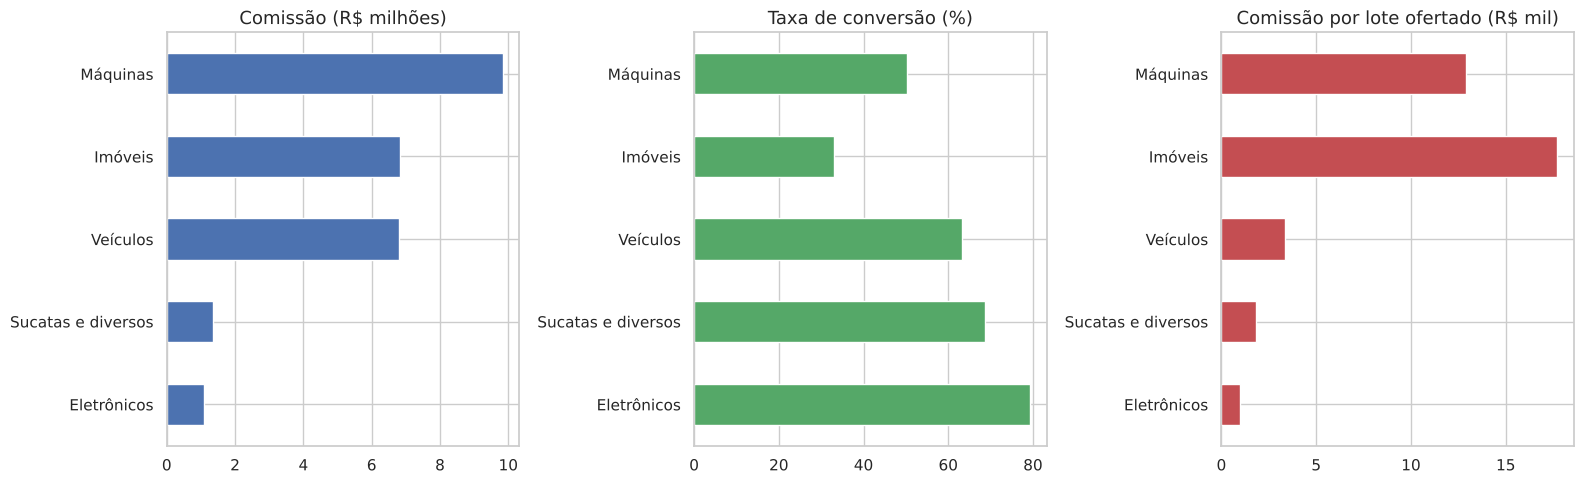

In [18]:
k_cat = kpis(tratada, "categoria").sort_values("comissao", ascending=False)   # KPIs por categoria
display(formatar_kpis(k_cat))

fig, ax = plt.subplots(1, 3, figsize=(16, 5))
k_cat["comissao"].div(1e6).plot.barh(ax=ax[0], color="#4C72B0"); ax[0].set_title("Comissão (R$ milhões)"); ax[0].invert_yaxis()
(k_cat["conversao"]*100).plot.barh(ax=ax[1], color="#55A868"); ax[1].set_title("Taxa de conversão (%)"); ax[1].invert_yaxis(); ax[1].set_ylabel("")
k_cat["comissao_por_lote"].div(1e3).plot.barh(ax=ax[2], color="#C44E52"); ax[2].set_title("Comissão por lote ofertado (R$ mil)"); ax[2].invert_yaxis(); ax[2].set_ylabel("")
ax[0].set_ylabel("")
plt.tight_layout(); plt.savefig(PASTA_SAIDA / "grafico_categorias.png", dpi=150); plt.show()

**Resposta.**
- **Máquinas** é a maior fonte de comissão (R$ 9,8 mi, ~38%), mesmo com GMV menor que Veículos e Imóveis: o **take rate de 9%** compensa.
- **Imóveis** tem o maior GMV (R$ 136 mi) e o maior ticket (R$ 1,07 mi), mas **converte só 33%** e paga o **menor take rate (5%)**.
- **Veículos** é o maior em volume de lotes, com conversão e take rate medianos (63% e 6%).
- **Eletrônicos** converte muito bem (79%) e tem o maior take rate (12%), mas o ticket é pequeno (~R$ 10 mil): rende só R$ 1,0 mil por lote ofertado.
- A leitura mais útil é a **comissão por lote ofertado**: Imóveis (R$ 17,7 mil) e Máquinas (R$ 12,9 mil) são 13 a 18 vezes mais valiosos que um lote de Eletrônicos.

### 10.3 Pergunta: o canal Online é melhor que o Presencial?

In [19]:
k_canal = kpis(tratada, "canal")                                        # KPIs por canal
display(formatar_kpis(k_canal))

# Teste qui-quadrado: a diferença de conversão entre canais é estatisticamente relevante?
tabela = pd.crosstab(tratada["canal"], tratada["vendido"])              # contagem canal x vendido
chi2, p, _, _ = chi2_contingency(tabela)                                # teste de independência
print(f"Qui-quadrado = {chi2:.1f} | p-valor = {p:.2e}")
print("Conclusão:", "diferença estatisticamente significativa (p < 0,05)" if p < 0.05 else "sem diferença significativa")

,lotes,vendidos,gmv,comissao,conversao,take_rate,ticket_medio,comissao_por_lote,part_comissao
canal,,,,,,,,,
Online,3918,2619,R$ 320.400.751,R$ 21.547.758,"66,8%","6,7%",R$ 122.337,R$ 5.500,"83,2%"
Presencial,1082,545,R$ 61.006.334,R$ 4.352.762,"50,4%","7,1%",R$ 111.938,R$ 4.023,"16,8%"


Qui-quadrado = 98.3 | p-valor = 3.53e-23
Conclusão: diferença estatisticamente significativa (p < 0,05)


**Resposta.** O Online responde por **83% da comissão** e converte **67%**, contra **50%** do Presencial. O p-valor é praticamente zero, então a diferença **não é acaso**. O ticket médio e o take rate são parecidos entre canais: a diferença está na **conversão**, não no preço nem na comissão.

*Cuidado:* o teste mostra que a diferença existe, mas **não prova que migrar um lote para o Online o fará vender** (correlação não é causalidade; o perfil dos lotes de cada canal pode diferir).

### 10.4 Gráfico principal: a conversão do Presencial é menor em todas as categorias

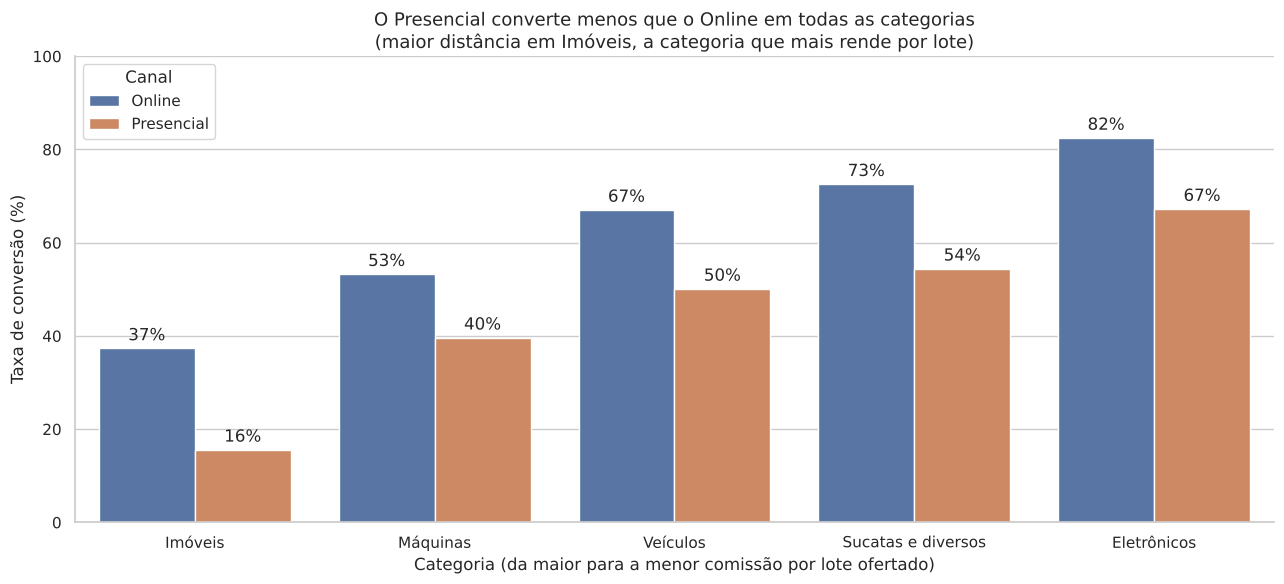

lotes  vendidos conversao  ticket_medio  \
categoria          canal                                                 
Eletrônicos        Online        868       716     82,5%     R$ 10.422   
                   Presencial    232       156     67,2%     R$ 10.649   
Imóveis            Online        308       115     37,3%  R$ 1.054.251   
                   Presencial     77        12     15,6%  R$ 1.263.394   
Máquinas           Online        597       318     53,3%    R$ 275.097   
                   Presencial    164        65     39,6%    R$ 329.396   
Sucatas e diversos Online        576       418     72,6%     R$ 26.818   
                   Presencial    158        86     54,4%     R$ 25.956   
Veículos           Online       1569      1052     67,0%     R$ 88.412   
                   Presencial    451       226     50,1%     R$ 90.891   

                              take_rate comissao_por_lote  
categoria          canal                                   
Eletrônicos        Online         12,0%          R$ 1.036  
                   Presencial     12,1%            R$ 868  
Imóveis            Online          5,0%         R$ 19.682  
                   Presencial      5,0%          R$ 9.845  
Máquinas           Online          9,0%         R$ 13.194  
                   Presencial      9,1%         R$ 11.920  
Sucatas e diversos Online         10,0%          R$ 1.947  
                   Presencial      9,9%          R$ 1.400  
Veículos           Online          6,0%          R$ 3.562  
                   Presencial      5,9%          R$ 2.699

In [20]:
k_cc = kpis(tratada, ["categoria", "canal"]).reset_index()              # KPIs por categoria x canal
ordem = k_cat.sort_values("comissao_por_lote", ascending=False).index.tolist()   # ordena por valor do lote

fig, ax = plt.subplots(figsize=(13, 6))
sns.barplot(data=k_cc, x="categoria", y=k_cc["conversao"]*100, hue="canal", order=ordem,
            palette={"Online": "#4C72B0", "Presencial": "#DD8452"}, ax=ax)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.0f%%", padding=3)                         # rótulos nas barras
ax.set_title("O Presencial converte menos que o Online em todas as categorias\n(maior distância em Imóveis, a categoria que mais rende por lote)")
ax.set_xlabel("Categoria (da maior para a menor comissão por lote ofertado)")
ax.set_ylabel("Taxa de conversão (%)"); ax.set_ylim(0, 100)
ax.legend(title="Canal"); sns.despine()
plt.tight_layout(); plt.savefig(PASTA_SAIDA / "grafico_principal_conversao.png", dpi=150); plt.show()

display(formatar_kpis(k_cc.set_index(["categoria", "canal"]))[["lotes", "vendidos", "conversao", "ticket_medio", "take_rate", "comissao_por_lote"]])

### 10.5 Pergunta: como os indicadores evoluem mês a mês?

,lotes,vendidos,gmv,comissao,conversao,take_rate,ticket_medio
mes,,,,,,,
2026-01,568,348,R$ 46.864.031,R$ 3.129.559,"61,3%","6,7%",R$ 134.667
2026-02,534,346,R$ 42.959.416,R$ 2.893.188,"64,8%","6,7%",R$ 124.160
2026-03,600,386,R$ 41.993.179,R$ 2.912.412,"64,3%","6,9%",R$ 108.791
2026-04,515,325,R$ 39.002.514,R$ 2.676.915,"63,1%","6,9%",R$ 120.008
2026-05,619,391,R$ 49.887.658,R$ 3.407.160,"63,2%","6,8%",R$ 127.590
2026-06,510,321,R$ 40.942.329,R$ 2.764.309,"62,9%","6,8%",R$ 127.546
2026-07,578,386,R$ 44.138.645,R$ 3.025.277,"66,8%","6,9%",R$ 114.349
2026-08,578,367,R$ 50.177.776,R$ 3.372.224,"63,5%","6,7%",R$ 136.724
2026-09,498,294,R$ 25.441.536,R$ 1.719.476,"59,0%","6,8%",R$ 86.536


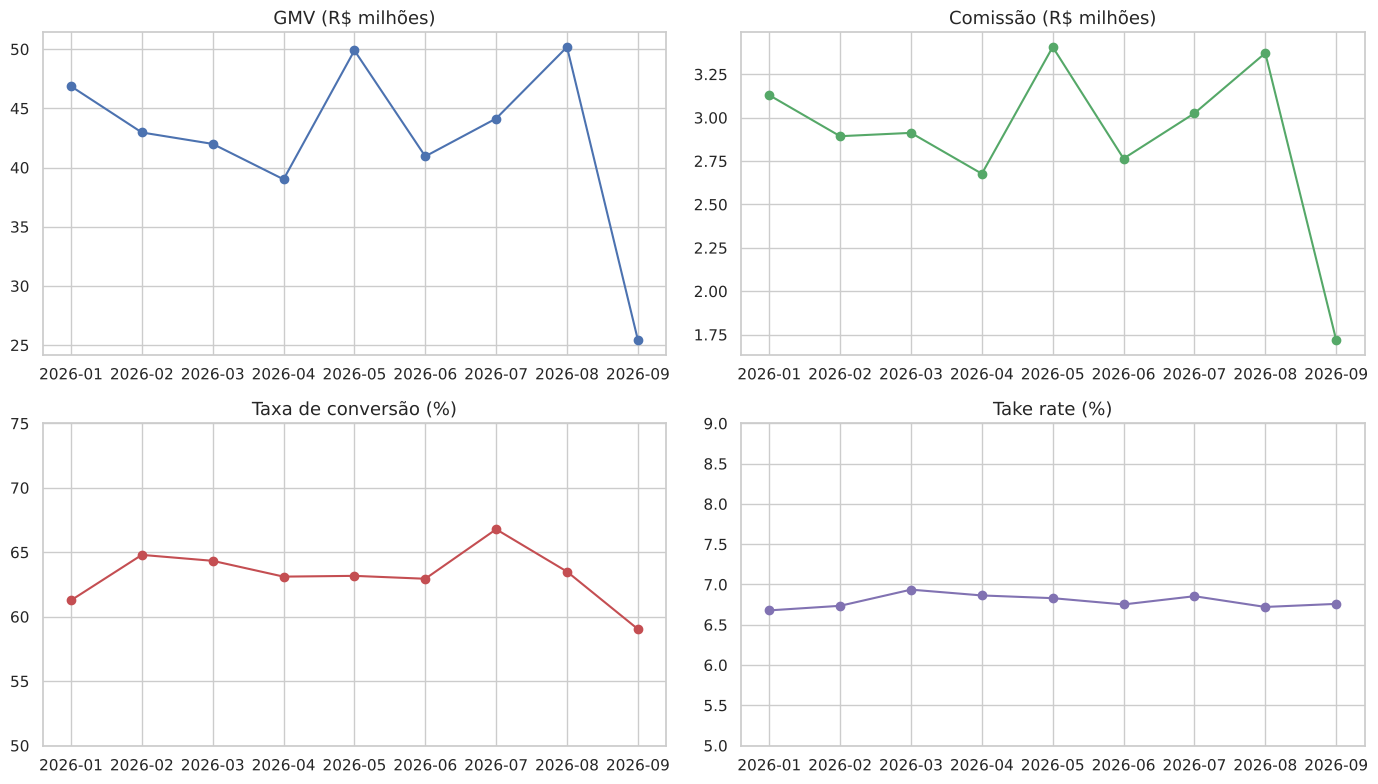

In [21]:
k_mes = kpis(tratada, "mes")                                            # KPIs por mês
display(formatar_kpis(k_mes)[["lotes", "vendidos", "gmv", "comissao", "conversao", "take_rate", "ticket_medio"]])

fig, ax = plt.subplots(2, 2, figsize=(14, 8))
(k_mes["gmv"]/1e6).plot(marker="o", ax=ax[0, 0], color="#4C72B0"); ax[0, 0].set_title("GMV (R$ milhões)")
(k_mes["comissao"]/1e6).plot(marker="o", ax=ax[0, 1], color="#55A868"); ax[0, 1].set_title("Comissão (R$ milhões)")
(k_mes["conversao"]*100).plot(marker="o", ax=ax[1, 0], color="#C44E52"); ax[1, 0].set_title("Taxa de conversão (%)"); ax[1, 0].set_ylim(50, 75)
(k_mes["take_rate"]*100).plot(marker="o", ax=ax[1, 1], color="#8172B2"); ax[1, 1].set_title("Take rate (%)"); ax[1, 1].set_ylim(5, 9)
for a in ax.flat: a.set_xlabel("")
plt.tight_layout(); plt.savefig(PASTA_SAIDA / "grafico_evolucao_mensal.png", dpi=150); plt.show()

**Resposta.** Volume de lotes, conversão (~59% a 67%) e take rate (~6,7% a 6,9%) ficam estáveis de janeiro a agosto. **Setembro destoa**: GMV e comissão caem cerca de 49% frente a agosto e a conversão é a menor do período (59%). Os lotes ofertados caíram cerca de 12% (498 contra média de 563 em jan–ago), mas a conversão caiu mais: o problema está sobretudo em **vender**, não só em **ofertar**. A seção seguinte mostra onde.

### 10.6 Pergunta: o que aconteceu em setembro?

In [22]:
conv_mes_cat = tratada.pivot_table(index="mes", columns="categoria", values="vendido_flag", aggfunc="mean")   # conversão por mês x categoria
display((conv_mes_cat*100).round(0).astype(int).astype(str) + "%")

# Setembro contra a média de jan a ago, por categoria
set_ = tratada[tratada["mes"] == "2026-09"]; ate_ago = tratada[tratada["mes"] < "2026-09"]
comp = pd.DataFrame({
    "conv_jan_ago": ate_ago.groupby("categoria")["vendido_flag"].mean(),
    "conv_set": set_.groupby("categoria")["vendido_flag"].mean(),
    "lotes_set": set_.groupby("categoria")["id_lote"].count(),
    "vendidos_set": set_.groupby("categoria")["vendido_flag"].sum(),
})
comp["queda_pp"] = (comp["conv_set"] - comp["conv_jan_ago"]) * 100
print("Setembro vs média jan-ago:")
display(comp.round(3))

# Quanto de comissão se perdeu em setembro frente à média mensal de jan-ago?
perda = k_mes.loc[k_mes.index < "2026-09", "comissao"].mean() - k_mes.loc["2026-09", "comissao"]
print("Comissão de setembro abaixo da média mensal jan-ago em:", brl(perda))

categoria,Eletrônicos,Imóveis,Máquinas,Sucatas e diversos,Veículos
mes,,,,,
2026-01,72%,40%,49%,70%,62%
2026-02,84%,34%,54%,63%,64%
2026-03,80%,29%,58%,64%,67%
2026-04,80%,32%,49%,72%,61%
2026-05,81%,39%,51%,70%,60%
2026-06,76%,32%,53%,65%,62%
2026-07,86%,38%,55%,71%,63%
2026-08,76%,41%,50%,65%,66%
2026-09,78%,13%,31%,77%,63%


Setembro vs média jan-ago:


,conv_jan_ago,conv_set,lotes_set,vendidos_set,queda_pp
categoria,,,,,
Eletrônicos,0.795,0.777,112,87,-1.775
Imóveis,0.357,0.130,46,6,-22.650
Máquinas,0.525,0.307,75,23,-21.811
Sucatas e diversos,0.676,0.772,79,61,9.582
Veículos,0.633,0.629,186,117,-0.401


Comissão de setembro abaixo da média mensal jan-ago em: R$ 1.303.154


**Resposta.** A queda se concentra em **Imóveis (de ~36% para 13%: 6 vendas em 46 lotes) e Máquinas (de ~53% para 31%)**. As outras categorias ficam no patamar normal. Como cada Imóvel vale mais de R$ 1 milhão, **poucas vendas a menos já derrubam o GMV do mês**.

*Cuidado:* são amostras pequenas (poucas dezenas de lotes por mês). Pode ser sazonalidade, atraso de fechamento de vendas do fim do período ou problema real. **Não é possível concluir a causa só com esta base**, mas o sinal justifica investigar.

### 10.7 Pergunta: quanto vale fechar a distância de conversão do Presencial?

In [23]:
# Simulação: e se, em cada categoria, o Presencial convertesse como o Online?
# Premissas: mesmos lotes presenciais, mesmo ticket e mesmo take rate observados no Presencial.
linhas = []
for cat in k_cat.index:
    on = k_cc[(k_cc["categoria"] == cat) & (k_cc["canal"] == "Online")].iloc[0]           # KPIs do Online
    pr = k_cc[(k_cc["categoria"] == cat) & (k_cc["canal"] == "Presencial")].iloc[0]       # KPIs do Presencial
    vendas_extra = pr["lotes"] * (on["conversao"] - pr["conversao"])                      # vendas adicionais
    ganho = vendas_extra * pr["ticket_medio"] * pr["take_rate"]                            # comissão adicional
    linhas.append({"categoria": cat, "lotes_presenciais": int(pr["lotes"]), "conv_presencial": pr["conversao"],
                   "conv_online": on["conversao"], "vendas_extra": vendas_extra, "comissao_extra": ganho})
sim = pd.DataFrame(linhas).set_index("categoria").sort_values("comissao_extra", ascending=False)
sim["part_no_ganho"] = sim["comissao_extra"] / sim["comissao_extra"].sum()
sim_fmt = sim.copy()
for c in ["conv_presencial", "conv_online", "part_no_ganho"]: sim_fmt[c] = sim_fmt[c].map(pct)
sim_fmt["comissao_extra"] = sim_fmt["comissao_extra"].map(brl); sim_fmt["vendas_extra"] = sim_fmt["vendas_extra"].round(0).astype(int)
display(sim_fmt)

ganho_total = sim["comissao_extra"].sum()
com_total = tratada["comissao_corrigida"].sum()
print(f"Ganho potencial (9 meses): {brl(ganho_total)} = {pct(ganho_total/com_total)} da comissão atual")
print(f"Cenário conservador (fechar só METADE da distância): {brl(ganho_total/2)} = {pct(ganho_total/2/com_total)}")

,lotes_presenciais,conv_presencial,conv_online,vendas_extra,comissao_extra,part_no_ganho
categoria,,,,,,
Imóveis,77,"15,6%","37,3%",17,R$ 1.058.093,"46,8%"
Máquinas,164,"39,6%","53,3%",22,R$ 672.399,"29,7%"
Veículos,451,"50,1%","67,0%",76,R$ 411.416,"18,2%"
Sucatas e diversos,158,"54,4%","72,6%",29,R$ 73.716,"3,3%"
Eletrônicos,232,"67,2%","82,5%",35,R$ 45.676,"2,0%"


Ganho potencial (9 meses): R$ 2.261.301 = 8,7% da comissão atual
Cenário conservador (fechar só METADE da distância): R$ 1.130.651 = 4,4%


**Resposta.** Se o Presencial convertesse como o Online, a comissão subiria cerca de **R$ 2,3 milhões (+8,7%)** em 9 meses, sendo **~47% do ganho só em Imóveis**. Fechando **metade** da distância, ainda seriam ~R$ 1,1 milhão.

*Premissas:* mesmo ticket e take rate do Presencial; lotes presenciais comparáveis aos online (pode não ser verdade, por exemplo se imóveis difíceis vão ao Presencial). É um **teto de oportunidade**, não uma previsão.

### 10.8 Visão complementar: UF

In [24]:
k_uf = kpis(tratada, "uf").sort_values("comissao", ascending=False)     # KPIs por estado
display(formatar_kpis(k_uf)[["lotes", "conversao", "comissao", "part_comissao", "comissao_por_lote"]])

,lotes,conversao,comissao,part_comissao,comissao_por_lote
uf,,,,,
SP,1689,"63,5%",R$ 8.519.748,"32,9%",R$ 5.044
MG,695,"61,9%",R$ 3.766.005,"14,5%",R$ 5.419
RJ,638,"63,3%",R$ 3.041.682,"11,7%",R$ 4.768
PR,351,"62,4%",R$ 2.132.484,"8,2%",R$ 6.075
RS,347,"64,0%",R$ 1.890.239,"7,3%",R$ 5.447
BA,324,"67,3%",R$ 1.864.702,"7,2%",R$ 5.755
GO,314,"65,6%",R$ 1.708.768,"6,6%",R$ 5.442
SC,331,"61,3%",R$ 1.578.041,"6,1%",R$ 4.767
PE,311,"61,1%",R$ 1.398.851,"5,4%",R$ 4.498


**Resposta.** SP concentra cerca de um terço dos lotes e da comissão. A conversão varia pouco entre estados (61% a 67%): **a UF não é a principal alavanca**; categoria e canal explicam muito mais.

## 11. Conclusão e relatório final

**Perfil geral (base tratada).** 5.000 lotes, 3.164 vendidos (63%), GMV de R$ 381 mi, comissão de R$ 25,9 mi e take rate de 6,8%.

**Insights acionáveis**

1. **Priorizar Imóveis e Máquinas.** Rendem R$ 17,7 mil e R$ 12,9 mil de comissão por lote ofertado, contra R$ 1,0 mil em Eletrônicos e R$ 1,8 mil em Sucatas. Juntas somam ~64% da comissão com 23% dos lotes. *Por quê:* cada ponto de conversão nessas categorias vale muito mais que em qualquer outra. Faz sentido concentrar captação, avaliação do lance inicial e divulgação aqui.
2. **Recuperar a conversão do Presencial.** Converte 50% contra 67% do Online, com diferença significativa (p ≈ 0) em **todas** as categorias. Fechar a distância vale até ~R$ 2,3 mi (+8,7%); metade disso já é ~R$ 1,1 mi. *Por quê:* o ticket e o take rate são iguais nos dois canais, então a perda está só em lotes que não vendem. Começar por Imóveis (16% vs 37%), onde está ~47% do ganho.
3. **Investigar a queda de setembro em Imóveis e Máquinas.** A conversão de Imóveis caiu de ~36% para 13% e a de Máquinas de ~53% para 31%, derrubando o GMV do mês em ~49%. *Por quê:* é onde está o dinheiro, e os lotes ofertados caíram só ~12% (498 contra média de 563), bem menos que a conversão. Confirmar se é atraso de fechamento, sazonalidade ou problema real antes de planejar 2027.

**Qualidade dos dados (insight de processo).** O sistema exportou duplicatas e comissões com casa decimal errada (x10), que inflaram a comissão em ~R$ 0,8 mi (~3,2%). *Por quê importa:* decisões de comissão tomadas sobre a base bruta estariam erradas. Vale corrigir na origem e criar validação automática.

## 12. Decisão recomendada
| Item | Definição |
|---|---|
| **Critério de decisão** | Priorizar onde cada lote ofertado rende mais comissão (comissão por lote) e onde a conversão está abaixo do potencial já provado pela própria empresa (Online) |
| **Ação** | (1) Plano de recuperação da conversão do Presencial, começando por Imóveis e Máquinas; (2) investigação da queda de setembro; (3) validação automática de duplicatas e comissão na exportação |
| **Responsável (sugestão)** | Diretoria comercial (1 e 2) e Tecnologia/Dados (3) |
| **Prazo (sugestão)** | Diagnóstico em 30 dias; plano e metas para o planejamento de 2027 |
| **Indicador de acompanhamento** | Conversão do Presencial por categoria (meta inicial: fechar metade da distância para o Online); comissão por lote ofertado; conversão mensal de Imóveis e Máquinas |

## 13. Premissas e limitações
- Base **fictícia**, de 9 meses; não permite medir sazonalidade anual.
- A base não traz custo, meta, comitente nem motivo de lote não vendido. Por isso o estudo olha **receita de comissão**, não lucro.
- Duplicatas foram removidas por serem cópias exatas (mesmo `id_lote` e mesmos valores). Assumimos que o lote foi leiloado uma única vez.
- Em erros de comissão, **assumimos que `valor_venda` e `comissao_pct` estão corretos** e que o erro está em `comissao_R$` (padrão exato de x10).
- Nenhum outlier foi removido: os valores altos são coerentes com a categoria.
- A simulação do Presencial é um **teto de oportunidade**: assume lotes comparáveis entre canais e não prova causalidade.
- Setembro tem amostras pequenas por categoria; a queda é um **sinal**, não uma conclusão causal.

## 14. Próximos passos e monitoramento
- **Mensalmente:** acompanhar conversão por categoria × canal e comissão por lote ofertado.
- **Imediato:** levantar com a área comercial o que ocorreu em setembro (Imóveis e Máquinas) e o perfil dos lotes do Presencial.
- **Refazer a análise** quando houver 12 meses de dados (para sazonalidade) ou se a conversão do Presencial mudar mais de 3 p.p.
- **Apresentação:** transformar as seções 10.4 (gráfico principal), 11 e 12 em até 6 slides, com o último slide "Como usei IA".

## 15. Exportação das saídas

In [25]:
# Dataset tratado, KPIs e relatório de qualidade em pasta padronizada (o arquivo original NÃO é alterado)
tratada.to_csv(PASTA_SAIDA / "base_tratada.csv", index=False, encoding="utf-8-sig")
with pd.ExcelWriter(PASTA_SAIDA / "kpis_lance_certo.xlsx") as xl:
    k_cat.reset_index().to_excel(xl, sheet_name="KPIs por categoria", index=False)
    k_canal.reset_index().to_excel(xl, sheet_name="KPIs por canal", index=False)
    k_cc.to_excel(xl, sheet_name="Categoria x canal", index=False)
    k_mes.reset_index().to_excel(xl, sheet_name="KPIs por mes", index=False)
    comp.reset_index().to_excel(xl, sheet_name="Setembro vs jan-ago", index=False)
    sim.reset_index().to_excel(xl, sheet_name="Simulacao Presencial", index=False)
    qualidade.to_excel(xl, sheet_name="Qualidade antes-depois", index=False)
print("Arquivos gerados em:", PASTA_SAIDA.resolve())
for f in sorted(PASTA_SAIDA.iterdir()): print(" -", f.name)

Arquivos gerados em: /home/claude/case_b/saidas
 - base_tratada.csv
 - grafico_categorias.png
 - grafico_evolucao_mensal.png
 - grafico_principal_conversao.png
 - kpis_lance_certo.xlsx


## 16. Checklist final de revisão
- [x] Arquivo original **não foi alterado** (tratamento só na cópia `tratada`)
- [x] Pergunta respondida: onde ganhar dinheiro e onde concentrar esforço em 2027
- [x] Números conferidos (asserts da seção 8 e checagem de comissão recalculada)
- [x] Inconsistências documentadas: duplicatas, comissão x10, arredondamento, outliers (mantidos)
- [x] Gráficos legíveis e com título que diz a conclusão
- [x] Decisão clara, com critério, ação, responsável, prazo e indicador

**Fim**